In [2]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor

In [3]:
df = pd.read_csv('data.csv')
df.head()

,date,atm_id,city,cash_withdrawals,avg_transaction_amount,cash_demand_lakh,is_weekend,day_of_month,month,day_of_week
0,2024-01-01,ATM_001,Bengaluru,482,2624.0,12.65,0,1,1,0
1,2024-01-02,ATM_001,Bengaluru,460,2873.0,13.22,0,2,1,1
2,2024-01-03,ATM_001,Bengaluru,488,2494.0,12.17,0,3,1,2
3,2024-01-04,ATM_001,Bengaluru,519,2985.0,15.49,0,4,1,3
4,2024-01-05,ATM_001,Bengaluru,457,2885.0,13.18,0,5,1,4


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   date                    731 non-null    str    
 1   atm_id                  731 non-null    str    
 2   city                    731 non-null    str    
 3   cash_withdrawals        731 non-null    int64  
 4   avg_transaction_amount  719 non-null    float64
 5   cash_demand_lakh        731 non-null    float64
 6   is_weekend              731 non-null    int64  
 7   day_of_month            731 non-null    int64  
 8   month                   731 non-null    int64  
 9   day_of_week             731 non-null    int64  
dtypes: float64(2), int64(5), str(3)
memory usage: 57.2 KB


In [5]:
df.isnull().sum()

date                       0
atm_id                     0
city                       0
cash_withdrawals           0
avg_transaction_amount    12
cash_demand_lakh           0
is_weekend                 0
day_of_month               0
month                      0
day_of_week                0
dtype: int64

In [6]:
df['date'] = pd.to_datetime(df['date'])

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   date                    731 non-null    datetime64[us]
 1   atm_id                  731 non-null    str           
 2   city                    731 non-null    str           
 3   cash_withdrawals        731 non-null    int64         
 4   avg_transaction_amount  719 non-null    float64       
 5   cash_demand_lakh        731 non-null    float64       
 6   is_weekend              731 non-null    int64         
 7   day_of_month            731 non-null    int64         
 8   month                   731 non-null    int64         
 9   day_of_week             731 non-null    int64         
dtypes: datetime64[us](1), float64(2), int64(5), str(2)
memory usage: 57.2 KB


In [8]:
df['avg_transaction_amount'] = df['avg_transaction_amount'].fillna(df['avg_transaction_amount'].median())

In [9]:
df.avg_transaction_amount.isnull().sum()

np.int64(0)

In [10]:
df[('city')].unique()

<StringArray>
['Bengaluru']
Length: 1, dtype: str

In [11]:
df[('atm_id')].unique()

<StringArray>
['ATM_001']
Length: 1, dtype: str

In [12]:
df = df.drop(columns=['atm_id','city'])

In [13]:
df['day_of_month'] = df['date'].dt.day
df['month'] = df['date'].dt.month
df['year'] = df['date'].dt.year
df['day_of_week'] = df['date'].dt.dayofweek
df['is_weekend'] = (df['day_of_week'] >= 5).astype(int)
df['is_month_end'] = df['date'].dt.is_month_end.astype(int)

In [14]:
df.head()

,date,cash_withdrawals,avg_transaction_amount,cash_demand_lakh,is_weekend,day_of_month,month,day_of_week,year,is_month_end
0,2024-01-01,482,2624.0,12.65,0,1,1,0,2024,0
1,2024-01-02,460,2873.0,13.22,0,2,1,1,2024,0
2,2024-01-03,488,2494.0,12.17,0,3,1,2,2024,0
3,2024-01-04,519,2985.0,15.49,0,4,1,3,2024,0
4,2024-01-05,457,2885.0,13.18,0,5,1,4,2024,0


In [15]:
X = df.drop(columns=['date','cash_demand_lakh'])
Y = df['cash_demand_lakh']

In [16]:
from sklearn.model_selection import train_test_split
split = int(len(df)*0.8)
X_train = X.iloc[:split]
X_test = X.iloc[split:]
Y_train = Y.iloc[:split]
Y_test = Y.iloc[split:]

In [17]:
model = RandomForestRegressor(n_estimators=100,random_state=42)

In [18]:
model.fit(X_train,Y_t)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [19]:
Y_pred = model.predict(X_test)
print(Y_pred)

[11.6252 11.8133 13.6971 13.1845 13.0924 11.7119 12.9306 12.0363 15.7828
 17.1937 16.543  13.2632 12.044  10.8069 12.5995 14.2912 16.5561 13.403
 17.3789 16.3991 15.176  16.4571 14.0291 15.4919 15.5511 15.1754 14.2423
 13.6909 14.8386 13.141  15.5117 12.7664 13.0602 12.0385 12.4154 11.5686
 10.5062 14.9661 16.8257 13.0994 11.857  11.337  11.4923 11.1144 14.4213
 15.3925 11.0878 13.9154 11.3212 15.4507 13.6205 15.0426 16.6542 14.4072
 12.6228 11.9131 14.4313 13.6173 13.4483 15.2331 11.711  11.3481 11.1268
 11.5208 13.1277 15.3315 15.4739 14.774  11.4382 11.7123 14.8848 13.2924
 15.5069 14.2005 16.7955 17.7816 16.3938 18.5174 17.6849 19.2714 19.9061
 13.5757 13.5842 17.3967 11.5567 14.6169 17.5989 14.4013 13.8659 14.087
 11.4413 10.697  12.127  15.6586 15.0582 14.6615 13.4694 11.586  13.0483
 12.4652 13.9196 15.0694 12.336  13.0712 13.4565 13.2733 12.8973 15.1226
 12.577  12.1544 13.7415 16.3115 14.2071 13.4032 17.4036 17.0706 14.0499
 15.8785 12.7552 12.7148 12.7304 15.1237 14.581  14.8

In [20]:
pd.DataFrame({'Actual': Y_test.values,'Predicted': Y_pred})


,Actual,Predicted
0,11.61,11.6252
1,11.87,11.8133
2,13.75,13.6971
3,13.10,13.1845
4,13.17,13.0924
...,...,...
142,21.17,19.9585
143,22.71,20.7582
144,18.93,18.9067
145,17.76,17.6523


In [21]:
output = pd.DataFrame({'Date': df.loc[X_test.index, 'date'].values,'Actual_Cash_Demand': Y_test.values,'Predicted_Cash_Demand': Y_pred})

output['Difference'] = abs(output['Actual_Cash_Demand'] - output['Predicted_Cash_Demand'])

print(output.head(10).round(2))

        Date  Actual_Cash_Demand  Predicted_Cash_Demand  Difference
0 2025-08-07               11.61                  11.63        0.02
1 2025-08-08               11.87                  11.81        0.06
2 2025-08-09               13.75                  13.70        0.05
3 2025-08-10               13.10                  13.18        0.08
4 2025-08-11               13.17                  13.09        0.08
5 2025-08-12               11.72                  11.71        0.01
6 2025-08-13               13.00                  12.93        0.07
7 2025-08-14               11.99                  12.04        0.05
8 2025-08-15               15.71                  15.78        0.07
9 2025-08-16               17.12                  17.19        0.07


C:\Users\Dhushanth S\AppData\Local\Temp\ipykernel_12472\3034317971.py:12: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(output.head(10).round(2))


In [22]:
tomorrow = df['date'].max() + pd.Timedelta(days=1)

tomorrow_data = pd.DataFrame([{
    'cash_withdrawals': df.iloc[-1]['cash_withdrawals'],
    'avg_transaction_amount': df.iloc[-1]['avg_transaction_amount'],
    'is_weekend': int(tomorrow.dayofweek >= 5),
    'day_of_month': tomorrow.day,
    'month': tomorrow.month,
    'day_of_week': tomorrow.dayofweek,
    'year': tomorrow.year,
    'is_month_end': int(tomorrow.is_month_end)
}])

prediction = model.predict(tomorrow_data)

print(f"Prediction Date: {tomorrow.date()}")
print(f"Tomorrow's Cash Demand: ₹ {prediction[0]:.2f} Lakhs")

Prediction Date: 2026-01-01
Tomorrow's Cash Demand: ₹ 17.87 Lakhs


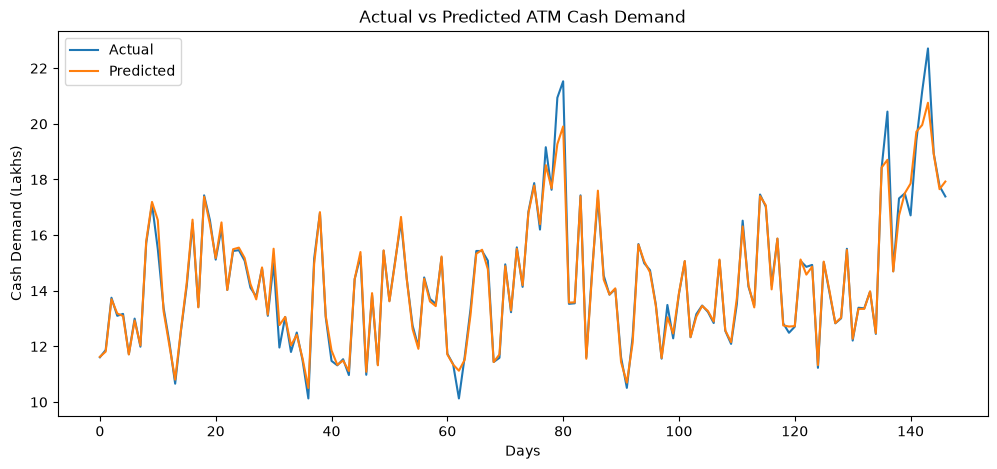

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.plot(Y_test.values, label='Actual')
plt.plot(Y_pred, label='Predicted')
plt.xlabel('Days')
plt.ylabel('Cash Demand (Lakhs)')
plt.title('Actual vs Predicted ATM Cash Demand')
plt.legend()
plt.show()

In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print(mean_absolute_error(Y_test, Y_pred))
print(np.sqrt(mean_squared_error(Y_test, Y_pred)))
print(r2_score(Y_test, Y_pred))

0.17586054421768668
0.37767917376964244
0.9752564284088436
